<a href="https://colab.research.google.com/github/Anshikatyagi008/EDA-Projects/blob/main/eda/Decision_Tree_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/creditcard.csv')

In [ ]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [ ]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
136737,81844,-10.972016,-10.165075,0.579235,1.914312,3.971221,-3.571746,-1.678594,-0.472964,1.746022,...,-1.950947,1.310955,3.551754,0.384646,1.611309,1.441667,2.522778,-1.41864956210692,117.02,0.0
136738,81844,1.424511,-1.481277,0.827126,-1.263302,-1.806258,0.125942,-1.553317,0.090583,-0.915535,...,-0.275377,-0.339339,-0.071301,-0.464163,0.329077,-0.146875,0.066696,0.0310399021239038,58.00,0.0
136739,81845,1.067404,0.087153,0.100938,0.986393,-0.082482,-0.412316,0.255298,-0.118738,-0.350417,...,0.113590,0.182403,-0.230636,0.035431,0.690598,-0.336135,-0.002191,0.0222817106909724,85.90,0.0
136740,81846,-0.833219,0.746826,1.747488,-0.016827,-0.406360,0.205399,-0.314283,0.605285,0.109673,...,-0.001167,0.019274,-0.191846,-0.389853,-0.148594,0.426455,-0.013927,0.0384589819489235,6.80,0.0
136741,81847,-0.418805,0.740210,-0.340755,-0.849297,2.720622,3.617123,0.524513,0.658118,0.207301,...,-0.160854,-0.264370,-0.207264,0.987706,0.237498,-0.580972,-0.119332,-,NaN,NaN


In [ ]:
df.shape

(136742, 31)

In [ ]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V20,V21,V22,V23,V24,V25,V26,V27,Amount,Class
count,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,...,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136742.000000,136741.000000,136741.000000
mean,51124.824633,-0.246165,0.010707,0.674727,0.140689,-0.284281,0.076938,-0.116757,0.064402,-0.089605,...,0.041908,-0.038564,-0.117482,-0.033986,0.011972,0.130526,0.023202,0.000746,91.595521,0.001923
std,20560.121115,1.817589,1.616407,1.270573,1.324460,1.309444,1.282327,1.165661,1.207558,1.090933,...,0.723193,0.715435,0.634982,0.595771,0.594931,0.437699,0.492354,0.389838,248.410997,0.043814
min,0.000000,-56.407510,-72.715728,-33.680984,-5.519697,-42.147898,-26.160506,-31.764946,-73.216718,-9.283925,...,-21.024817,-34.830382,-10.933144,-44.807735,-2.836627,-10.295397,-2.534330,-22.565679,0.000000,0.000000
25%,37550.250000,-1.018868,-0.568978,0.171846,-0.715742,-0.906530,-0.662302,-0.604401,-0.131568,-0.714480,...,-0.169856,-0.225762,-0.546484,-0.172164,-0.324026,-0.135899,-0.326276,-0.060303,6.040000,0.000000
50%,52958.500000,-0.263616,0.099794,0.751062,0.167549,-0.316486,-0.176668,-0.065283,0.079767,-0.152871,...,-0.026766,-0.059021,-0.094133,-0.045246,0.068760,0.167579,-0.066402,0.011723,24.000000,0.000000
75%,68256.750000,1.158182,0.769964,1.364977,0.996115,0.237199,0.463398,0.409667,0.372229,0.487614,...,0.164767,0.114086,0.302201,0.083035,0.408407,0.419418,0.287948,0.086583,81.560000,0.000000
max,81847.000000,1.960497,18.902453,9.382558,16.715537,34.801666,22.529298,36.677268,20.007208,15.594995,...,39.420904,27.202839,10.503090,19.002942,4.016342,5.541598,3.517346,12.152401,19656.530000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 136742 entries, 0 to 136741
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    136742 non-null  int64  
 1   V1      136742 non-null  float64
 2   V2      136742 non-null  float64
 3   V3      136742 non-null  float64
 4   V4      136742 non-null  float64
 5   V5      136742 non-null  float64
 6   V6      136742 non-null  float64
 7   V7      136742 non-null  float64
 8   V8      136742 non-null  float64
 9   V9      136742 non-null  float64
 10  V10     136742 non-null  float64
 11  V11     136742 non-null  float64
 12  V12     136742 non-null  float64
 13  V13     136742 non-null  float64
 14  V14     136742 non-null  float64
 15  V15     136742 non-null  float64
 16  V16     136742 non-null  float64
 17  V17     136742 non-null  float64
 18  V18     136742 non-null  float64
 19  V19     136742 non-null  float64
 20  V20     136742 non-null  float64
 21  V21     13

In [ ]:
df.dtypes

,0
Time,int64
V1,float64
V2,float64
V3,float64
V4,float64
V5,float64
V6,float64
V7,float64
V8,float64
V9,float64


In [ ]:
df.isnull().sum().sum()

np.int64(2)

In [ ]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

In [ ]:
df.columns.tolist()

['Time',
 'V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'Amount',
 'Class']

In [ ]:
df.duplicated().sum()


np.int64(1081)

In [ ]:
df = df.drop_duplicates()
print("Shape after removing duplicates: ", df.shape)
print("Remaining duplicacy: ", df.duplicated().sum().sum())

Shape after removing duplicates:  (283726, 31)
Remaining duplicacy:  0


In [ ]:
df[df.isnull().any(axis=1)]

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class


In [ ]:
df.isnull().sum().sum()

np.int64(0)

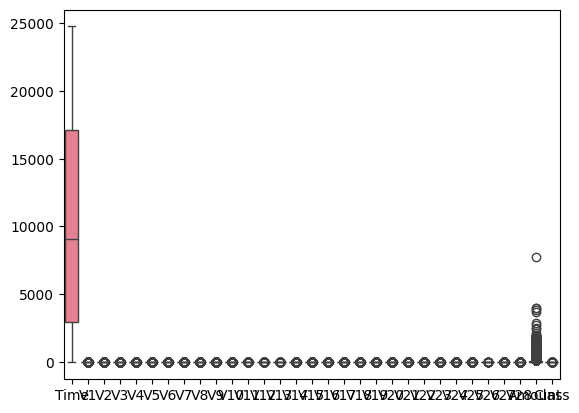

In [3]:
sns.boxplot(data=df)
plt.show()

Class
0    283253
1       473
Name: count, dtype: int64


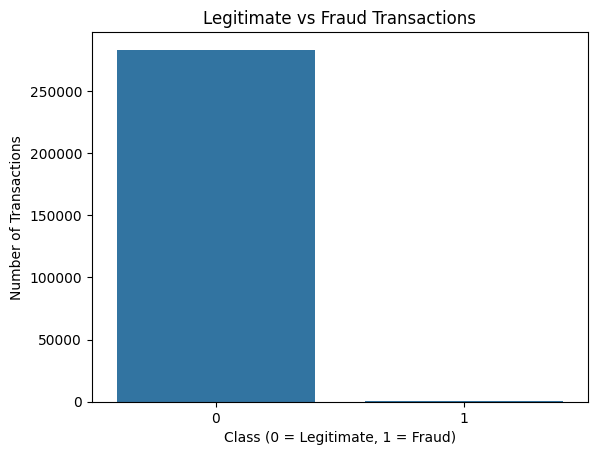

In [ ]:
print(df["Class"].value_counts())

sns.countplot(x="Class", data=df)
plt.title("Legitimate vs Fraud Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [ ]:
X = df.drop("Class", axis=1)
y = df["Class"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (283726, 30)
Target shape: (283726,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (226980, 30)
Testing features: (56746, 30)


In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

print("Decision Tree model created successfully!")

Decision Tree model created successfully!


In [ ]:
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [ ]:
y_pred_dt = dt_model.predict(X_test)

print("Predictions completed!")
print("First 20 predictions:")
print(y_pred_dt[:20])

Predictions completed!
First 20 predictions:
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Accuracy: 0.9953124449300391

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.23      0.78      0.36        95

    accuracy                           1.00     56746
   macro avg       0.62      0.89      0.68     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix:
[[56406   245]
 [   21    74]]
